# Brain Tumor MRI Classification

CNN classifier for 4 classes of brain MRI scans: glioma, meningioma, no tumor, pituitary.
Dataset: Kaggle `tombackert/brain-tumor-mri-data` (7,153 images).

## 1. Setup

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd
import torch
from PIL import Image
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.__version__, device)
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

2.14.1+cu126 cuda
NVIDIA GeForce RTX 3050 6GB Laptop GPU


## 2. Load the data

In [3]:
data_path = r"C:\Users\prabh\Downloads\brain-tumor-mri-dataset"

for folder in os.listdir(data_path):
    folder_path = os.path.join(data_path, folder)
    print(folder, len(os.listdir(folder_path)))

glioma 1621
meningioma 1775
notumor 2000
pituitary 1757


In [4]:
data = []

for folder in os.listdir(data_path):
    folder_path = os.path.join(data_path, folder)
    for image_name in os.listdir(folder_path):
        image_path = os.path.join(folder_path, image_name)
        record = {}
        record["path"] = image_path
        record['label'] = folder
        data.append(record)

df = pd.DataFrame(data=data)
print(len(df))
df['label'].value_counts()

7153


label
notumor       2000
meningioma    1775
pituitary     1757
glioma        1621
Name: count, dtype: int64

## 3. Explore the images

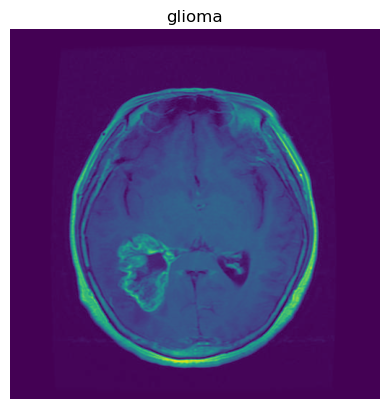

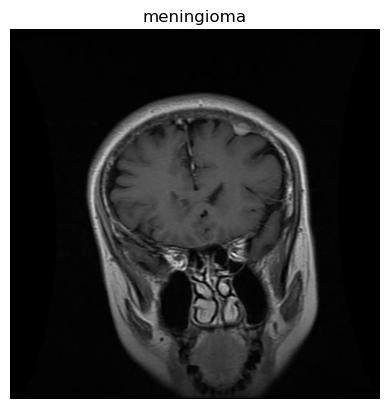

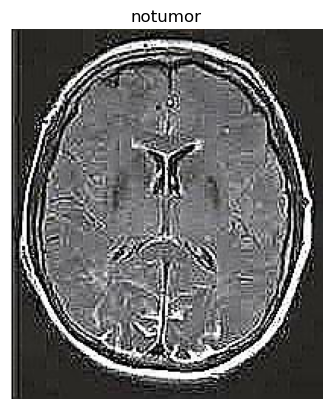

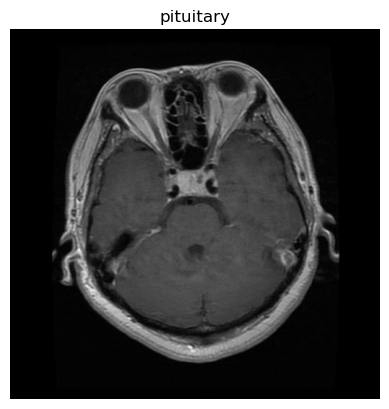

In [5]:
for folder in os.listdir(data_path):
    folder_path = os.path.join(data_path, folder)

    image_name = os.listdir(folder_path)[0]
    image_path = os.path.join(folder_path, image_name)

    image = plt.imread(image_path)

    plt.imshow(image)
    plt.title(folder)
    plt.axis("off")
    plt.show()

In [6]:
# image sizes and channel counts vary a lot (some grayscale, some RGB)
for folder in os.listdir(data_path):
    folder_path = os.path.join(data_path, folder)

    shapes = set()

    for image_name in os.listdir(folder_path)[:100]:
        image_path = os.path.join(folder_path, image_name)
        image = plt.imread(image_path)
        shapes.add(image.shape)

    print(folder, shapes)

glioma {(512, 512), (512, 512, 3)}
meningioma {(510, 485, 3), (336, 264, 3), (512, 512), (396, 411, 3), (237, 212, 3), (356, 286, 3), (216, 224, 3), (512, 512, 3), (365, 306, 3), (395, 366, 3), (342, 290, 3), (284, 324, 3), (306, 278, 3), (216, 234, 3), (1427, 1275, 3), (358, 314, 3)}
notumor {(168, 300, 3), (444, 468, 3), (674, 648, 3), (250, 201, 3), (442, 442, 3), (848, 785, 3), (442, 400, 3), (415, 339, 3), (225, 225, 3), (244, 235, 3), (243, 207, 3), (540, 504, 3), (250, 236, 3), (248, 208, 3), (340, 339, 3), (417, 428, 3), (275, 220, 3), (630, 630, 3), (310, 329, 3), (252, 200, 3), (449, 359, 3), (228, 235, 3), (236, 214, 3), (282, 230, 3), (236, 236, 3), (262, 227, 3), (244, 206, 3), (201, 173, 3), (257, 236, 3), (221, 228, 3), (649, 926, 3), (512, 512, 3), (680, 680, 3), (217, 232, 3), (664, 550, 3), (600, 494, 3), (234, 218, 3), (1024, 1024), (257, 196, 3), (238, 212, 3), (400, 393, 3), (251, 201, 3), (234, 215, 3), (294, 236, 3), (280, 420, 3), (192, 192, 3), (222, 227, 3), (

## 4. Train / validation / test split (70 / 15 / 15, stratified)

In [7]:
train_df, temp_df = train_test_split(df, test_size=0.3, random_state=42, stratify=df['label'])
validation_df, test_df = train_test_split(temp_df, test_size=.5, random_state=42, stratify=temp_df['label'])

print(len(train_df), len(validation_df), len(test_df))

5007 1073 1073


In [8]:
for name, split in [("train", train_df), ("validation", validation_df), ("test", test_df)]:
    print(name)
    print(split['label'].value_counts(), "\n")

train
label
notumor       1400
meningioma    1242
pituitary     1230
glioma        1135
Name: count, dtype: int64 

validation
label
notumor       300
meningioma    266
pituitary     264
glioma        243
Name: count, dtype: int64 

test
label
notumor       300
meningioma    267
pituitary     263
glioma        243
Name: count, dtype: int64 



## 5. Labels to numbers

In [9]:
classes = sorted(df['label'].unique())

label_to_idx = dict()
for i, name in enumerate(classes):
    label_to_idx[name] = i

idx_to_label = {}
for name, i in label_to_idx.items():
    idx_to_label[i] = name

print(label_to_idx)
print(idx_to_label)

{'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
{0: 'glioma', 1: 'meningioma', 2: 'notumor', 3: 'pituitary'}


In [10]:
train_df['label_idx'] = train_df['label'].map(label_to_idx)
validation_df['label_idx'] = validation_df['label'].map(label_to_idx)
test_df['label_idx'] = test_df['label'].map(label_to_idx)

# should all be 0: every label found a match
print(train_df['label_idx'].isna().sum(), validation_df['label_idx'].isna().sum(), test_df['label_idx'].isna().sum())

0 0 0


## 6. Dataset class

In [11]:
class MRIDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        path = row['path']
        label = row['label_idx']
        img = Image.open(path)
        img = img.convert("RGB")
        if self.transform is not None:
            img = self.transform(img)
        return img, label

## 7. Transforms

In [12]:
# training: resize + light augmentation + ImageNet normalization
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),   # every image becomes 224x224
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),           # PIL image -> tensor, pixel values 0-255 scaled to 0-1
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# validation / test: same preprocessing, no randomness
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

## 8. Datasets and loaders

In [13]:
train_ds = MRIDataset(train_df, transform=train_transform)
validation_ds = MRIDataset(validation_df, transform=eval_transform)
test_ds = MRIDataset(test_df, transform=eval_transform)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
validation_loader = DataLoader(validation_ds, batch_size=32, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False)

print(len(train_loader), len(validation_loader), len(test_loader))

157 34 34


## 9. Check a batch

In [14]:
images, labels = next(iter(train_loader))
print(images.shape)   # [32, 3, 224, 224]
print(labels.shape)   # [32]
print(images.min().item(), images.max().item())

torch.Size([32, 3, 224, 224])
torch.Size([32])
-2.1179039478302 2.640000104904175


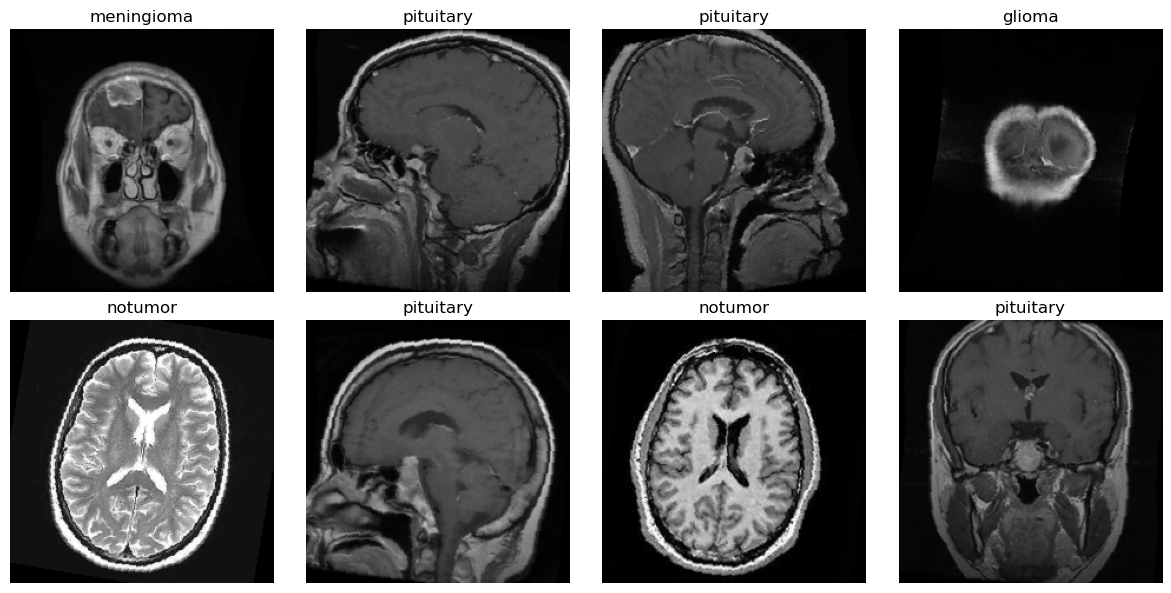

In [15]:
# undo the normalization just for plotting
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    img = images[i] * std + mean
    label_name = idx_to_label[labels[i].item()]

    ax.imshow(img.permute(1, 2, 0).clamp(0, 1))
    ax.set_title(label_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 10. Baseline CNN

In [16]:
model = nn.Sequential(
    nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),
    nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),
    nn.Flatten(),
    nn.Linear(in_features=32 * 56 * 56, out_features=4)
)
model.to(device)

print(sum(p.numel() for p in model.parameters()))

406500


## 11. Train (10 epochs, keep the best epoch by validation loss)

In [17]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model.parameters(), lr=1e-3)

In [18]:
best_val = float("inf")
best_epoch = 0
train_losses = []
val_losses = []
val_accs = []

for epoch in range(1, 11):
    # ---- training ----
    model.train()
    running_loss = 0
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()           # clear old gradients
        logits = model(images)          # compute scores
        loss = criterion(logits, labels)
        loss.backward()                 # backpropagate gradients
        optimizer.step()                # update weights
        running_loss += loss.item() * len(labels)
    train_loss = running_loss / len(train_ds)

    # ---- validation ----
    model.eval()
    total_loss = 0
    correct = 0

    with torch.no_grad():
        for images, labels in validation_loader:
            images = images.to(device)
            labels = labels.to(device)
            logits = model(images)
            loss = criterion(logits, labels)

            total_loss += loss.item() * len(labels)
            preds = logits.argmax(dim=1)
            correct += (preds == labels).sum().item()

    val_loss = total_loss / len(validation_ds)
    val_acc = correct / len(validation_ds)

    # ---- keep the best epoch ----
    if val_loss < best_val:
        best_val = val_loss
        best_epoch = epoch
        best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}

    # ---- save + print ----
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_accs.append(val_acc)
    print(f"epoch {epoch}: train loss {train_loss:.3f} | val loss {val_loss:.3f} | val acc {val_acc:.1%}")

model.load_state_dict(best_state)   # restore the best weights
print(f"best epoch: {best_epoch}, val loss {best_val:.3f}")

epoch 1: train loss 0.753 | val loss 0.425 | val acc 84.2%
epoch 2: train loss 0.380 | val loss 0.327 | val acc 88.1%
epoch 3: train loss 0.281 | val loss 0.289 | val acc 90.5%
epoch 4: train loss 0.229 | val loss 0.239 | val acc 91.6%
epoch 5: train loss 0.198 | val loss 0.221 | val acc 92.5%
epoch 6: train loss 0.165 | val loss 0.236 | val acc 89.8%
epoch 7: train loss 0.136 | val loss 0.213 | val acc 93.8%
epoch 8: train loss 0.122 | val loss 0.258 | val acc 91.7%
epoch 9: train loss 0.096 | val loss 0.213 | val acc 94.3%
epoch 10: train loss 0.107 | val loss 0.216 | val acc 93.6%
best epoch: 9, val loss 0.213


## 12. Training curves

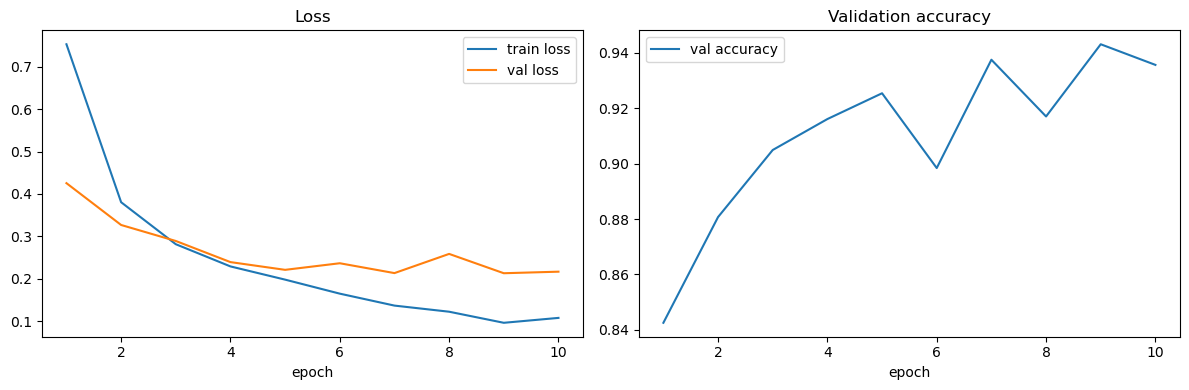

In [19]:
epochs = range(1, len(train_losses) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# left plot: loss
axes[0].plot(epochs, train_losses, label="train loss")
axes[0].plot(epochs, val_losses, label="val loss")
axes[0].set_xlabel("epoch")
axes[0].set_title("Loss")
axes[0].legend()

# right plot: validation accuracy
axes[1].plot(epochs, val_accs, label="val accuracy")
axes[1].set_xlabel("epoch")
axes[1].set_title("Validation accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

## 13. Save the best weights

In [20]:
torch.save(model.state_dict(), "baseline_cnn_best.pt")